# Temporary: raw-image signature training (no preprocessing)

Trains the Stage 3 ConvNeXt-Tiny embeddings on the **raw** CEDAR + BHSig260 images
with `--resize-only`, so no Stage 2.2 crop / whitening / binarization is applied.

This notebook also saves the training log, plots the training curves, evaluates on the
held-out test signers, and sweeps a few fixed similarity thresholds.

**Before running:** upload `sigver_raw.zip` as a Kaggle Dataset (it extracts to
`manifest.csv` + `raw/...`), enable a GPU accelerator, and turn on Internet (for the
ImageNet weights).

In [1]:
# --- Setup: code + dependencies ---------------------------------------------
%cd /kaggle/working
!rm -rf sigver && git clone https://acharyayush@github.com/yogeshY0/Signature-Verification.git sigver
%cd /kaggle/working/sigver
!pip install -q timm opencv-python-headless matplotlib

# Raw .tif scans make OpenCV print a harmless "TIFF Software tag" warning per file.
import os
os.environ["OPENCV_LOG_LEVEL"] = "ERROR"

/kaggle/working
Cloning into 'sigver'...
remote: Enumerating objects: 146, done.
remote: Counting objects: 100% (146/146), done.
remote: Compressing objects: 100% (106/106), done.
remote: Total 146 (delta 77), reused 108 (delta 39), pack-reused 0 (from 0)
Receiving objects: 100% (146/146), 977.27 KiB | 32.58 MiB/s, done.
Resolving deltas: 100% (77/77), done.
/kaggle/working/sigver


In [2]:
# --- Paths -------------------------------------------------------------------
DATA = "/kaggle/input/datasets/acharyayush/raw-sign-dataset"        # dataset root: manifest.csv + raw/
RUN = "ckpt_raw"                          # checkpoint folder under /kaggle/working
CKPT = f"/kaggle/working/{RUN}/best_model.pt"
LOG = "/kaggle/working/training_log.txt"  # epoch JSON lines for analyze_log
CURVES = "/kaggle/working/curves.png"     # training-curve plot
EVAL_JSON = "/kaggle/working/eval_default.json"

!ls $DATA && head -2 $DATA/manifest.csv

manifest.csv  raw




In [3]:
# --- Train on RAW images (no Stage 2.2 preprocessing) ------------------------
# --resize-only    : read raw scans, grayscale, resize to 192x384, normalize
# --negatives auto : EER/accuracy vs skilled forgeries (present in this dataset)
!python -m training.train_siamese --manifest $DATA/manifest.csv \
  --resize-only --negatives auto \
  --output-dir /kaggle/working/{RUN} \
  --device cuda --workers 2 \
  --phase1-epochs 5 --phase2-epochs 30 --lr-schedule cosine --select-by eer \
  2>&1 | tee {LOG}

Dataset-balanced sampling | signers/dataset: {'BHSig': 182, 'CEDAR': 38} -> signers per batch: {'BHSig': 6, 'CEDAR': 6}
Using device: cuda
{"phase": "warmup", "epoch": 1, "lr": 0.001, "train": {"loss": 0.27210300533395065, "mean_positive": 0.7292074655231676, "mean_negative": 0.7572030236846522, "active_fraction": 0.9978070196352506}, "validation": {"loss": 0.19864656403660774, "mean_positive": 0.40976983308792114, "mean_negative": 0.5190780684351921, "active_fraction": 0.9375000149011612}, "validation_eer_skilled": 0.2182133677994781, "validation_accuracy_skilled": {"0.7": 0.5379157427937916, "0.8": 0.6572062084257206, "0.9": 0.774279379157428}}
{"phase": "warmup", "epoch": 2, "lr": 0.000905463412215599, "train": {"loss": 0.22920593697773783, "mean_positive": 0.7564604627458673, "mean_negative": 0.8290208640851473, "active_fraction": 0.9736842168004889}, "validation": {"loss": 0.17671756446361542, "mean_positive": 0.47203123569488525, "mean_negative": 0.6155452281236649, "active_fract

epoch phase      train_loss  val_loss  val_gap
    1 warmup         0.2721    0.1986    0.109
    2 warmup         0.2292    0.1767    0.144
    3 warmup         0.2178    0.1679    0.170
    4 warmup         0.1775    0.1495    0.197
    5 warmup         0.1697    0.1449    0.207
    6 fine_tune      0.2624    0.1125    0.248
    7 fine_tune      0.1963    0.0917    0.281
    8 fine_tune      0.1719    0.0869    0.285
    9 fine_tune      0.1376    0.0880    0.275
   10 fine_tune      0.1357    0.0938    0.276
   11 fine_tune      0.1301    0.0938    0.286
   12 fine_tune      0.1150    0.0684    0.339
   13 fine_tune      0.0962    0.0701    0.350
   14 fine_tune      0.0905    0.0685    0.324
   15 fine_tune      0.0941    0.0691    0.321
   16 fine_tune      0.0716    0.0598    0.351
   17 fine_tune      0.0712    0.0709    0.337
   18 fine_tune      0.0621    0.0746    0.342
   19 fine_tune      0.0594    0.0540    0.396
   20 fine_tune      0.0537    0.0583    0.393
   21 fine_tu

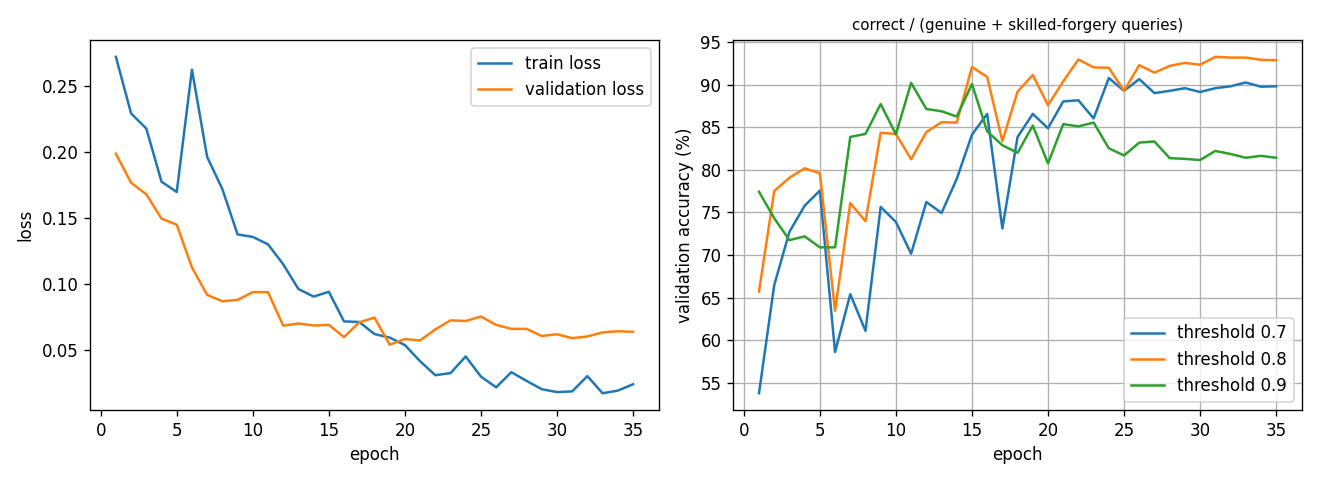

In [4]:
# --- Training curves ---------------------------------------------------------
!python -m training.analyze_log {LOG} --plot {CURVES}

from IPython.display import Image, display
display(Image(CURVES))

In [5]:
# --- Evaluate on the held-out test signers -----------------------------------
# Threshold is chosen on the validation signers (EER) and applied to test.
!python -m training.evaluate --checkpoint {CKPT} --manifest $DATA/manifest.csv \
  --resize-only --negatives auto \
  --device cuda --workers 2 --bootstrap 1000 \
  2>&1 | tee {EVAL_JSON}

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/kaggle/working/sigver/training/evaluate.py", line 372, in <module>
    main()
    ~~~~^^
  File "/kaggle/working/sigver/training/evaluate.py", line 340, in main
    name: _summary(
          ~~~~~~~~^
        test_scores,
        ^^^^^^^^^^^^
    ...<4 lines>...
        negatives_mode=args.negatives,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/kaggle/working/sigver/training/evaluate.py", line 252, in _summary
    "confidence_95": _bootstrap(
                     ~~~~~~~~~~^
        scores, signers, threshold, resamples, dataset_only, negatives_mode
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ),
    ^
  File "/kaggle/working/sigver/training/evaluate.py", line 239, in _bootstrap
    key: [float(np.percentile([d[key] for d in draws], q)) for q in (2.5, 97.5)]
                ~~~~~~~~~~~~~^^^

In [6]:
# --- Accuracy at fixed similarity thresholds (bootstrap off for speed) -------
for t in [0.7, 0.8, 0.85, 0.9]:
    print("=== threshold", t)
    !python -m training.evaluate --checkpoint {CKPT} --manifest $DATA/manifest.csv \
      --resize-only --negatives auto \
      --device cuda --workers 2 --bootstrap 0 --threshold {t} \
      2>&1 | grep -E "threshold_used|accuracy_skilled|far_skilled_at_threshold|frr_at_threshold" | head -5

=== threshold 0.7
  "threshold_used": 0.7,
    "accuracy_skilled": 0.8226164079822617,
    "balanced_accuracy_skilled": 0.85180749934636,
    "far_skilled_at_threshold": 0.28854625550660795,
    "frr_at_threshold": 0.007838745800671893,
=== threshold 0.8
  "threshold_used": 0.8,
    "accuracy_skilled": 0.9042128603104213,
    "balanced_accuracy_skilled": 0.9097150623301153,
    "far_skilled_at_threshold": 0.11674008810572688,
    "frr_at_threshold": 0.06382978723404255,
=== threshold 0.85
  "threshold_used": 0.85,
    "accuracy_skilled": 0.9104212860310421,
    "balanced_accuracy_skilled": 0.9009727312939768,
    "far_skilled_at_threshold": 0.053597650513950074,
    "frr_at_threshold": 0.1444568868980963,
=== threshold 0.9
  "threshold_used": 0.9,
    "accuracy_skilled": 0.8815964523281596,
    "balanced_accuracy_skilled": 0.8532031644393578,
    "far_skilled_at_threshold": 0.010279001468428781,
    "frr_at_threshold": 0.28331466965285557,


In [7]:
# --- Saved checkpoint --------------------------------------------------------
!ls -lh {CKPT}

-rw-r--r-- 1 root root 109M Nov 11 17:26 /kaggle/working/ckpt_raw/best_model.pt


### Notes

- **Saving the model:** use **Save Version -> Save & Run All (Commit)** so the run
  survives closing the tab, then download `best_model.pt` from the Output tab.
- **Thresholds:** the default evaluation picks the threshold at the validation EER and
  applies it unchanged to the test signers. The sweep cell applies fixed thresholds
  (`--threshold`) for comparison; a threshold chosen by looking at test results is not
  an honest estimate.
- **Resize mode:** `--resize-mode stretch` forces the image to 192x384 instead of the
  default aspect-preserving resize with white padding.
- **Negatives:** `--negatives auto` uses skilled forgeries when present (this dataset
  has them) and falls back to random/different-signer pairs otherwise.